# Data Understanding

In [54]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [55]:
movies_pre = pd.read_csv("tmdb_5000_movies.csv")
credits = pd.read_csv("tmdb_5000_credits.csv", engine='python', on_bad_lines='skip')

In [56]:
movies = pd.merge(movies_pre,     credits[["movie_id", "cast", "crew"]],
    left_on="id",
    right_on="movie_id",
    how="left",
    validate="one_to_one")

In [57]:
movies.isna().sum()
movies.shape

(4803, 23)

In [58]:
movies['release_date'] = pd.to_datetime(movies['release_date'])
movies['release_year'] = movies['release_date'].dt.year

In [59]:
movies.describe()

,budget,id,popularity,release_date,revenue,runtime,vote_average,vote_count,movie_id,release_year
count,4.803000e+03,4803.000000,4803.000000,4802,4.803000e+03,4801.000000,4803.000000,4803.000000,4803.000000,4802.000000
mean,2.904504e+07,57165.484281,21.492301,2002-12-27 23:45:54.352353280,8.226064e+07,106.875859,6.092172,690.217989,57165.484281,2002.468763
min,0.000000e+00,5.000000,0.000000,1916-09-04 00:00:00,0.000000e+00,0.000000,0.000000,0.000000,5.000000,1916.000000
25%,7.900000e+05,9014.500000,4.668070,1999-07-14 00:00:00,0.000000e+00,94.000000,5.600000,54.000000,9014.500000,1999.000000
50%,1.500000e+07,14629.000000,12.921594,2005-10-03 00:00:00,1.917000e+07,103.000000,6.200000,235.000000,14629.000000,2005.000000
75%,4.000000e+07,58610.500000,28.313505,2011-02-16 00:00:00,9.291719e+07,118.000000,6.800000,737.000000,58610.500000,2011.000000
max,3.800000e+08,459488.000000,875.581305,2017-02-03 00:00:00,2.787965e+09,338.000000,10.000000,13752.000000,459488.000000,2017.000000
std,4.072239e+07,88694.614033,31.816650,NaN,1.628571e+08,22.611935,1.194612,1234.585891,88694.614033,12.414354


In [60]:
categorical = ['genres','keywords','original_language','production_companies','spoken_languages']
for col in categorical:
    print(movies[col].value_counts())

genres
[{"id": 18, "name": "Drama"}]                                                                                                                                                                    370
[{"id": 35, "name": "Comedy"}]                                                                                                                                                                   282
[{"id": 18, "name": "Drama"}, {"id": 10749, "name": "Romance"}]                                                                                                                                  164
[{"id": 35, "name": "Comedy"}, {"id": 10749, "name": "Romance"}]                                                                                                                                 144
[{"id": 35, "name": "Comedy"}, {"id": 18, "name": "Drama"}]                                                                                                                                      142
        

In [61]:
movies_clean = movies[(movies["budget"] != 0) & (movies["revenue"] != 0)]
df = movies_clean.dropna(subset=['id'])
print(df.shape)
for col in categorical:
    print(df[col].value_counts())

(3229, 24)
genres
[{"id": 18, "name": "Drama"}]                                                                                                                                       204
[{"id": 35, "name": "Comedy"}]                                                                                                                                      197
[{"id": 18, "name": "Drama"}, {"id": 10749, "name": "Romance"}]                                                                                                      96
[{"id": 35, "name": "Comedy"}, {"id": 10749, "name": "Romance"}]                                                                                                     87
[{"id": 35, "name": "Comedy"}, {"id": 18, "name": "Drama"}]                                                                                                          70
                                                                                                                                              

In [62]:
df.describe()

,budget,id,popularity,release_date,revenue,runtime,vote_average,vote_count,movie_id,release_year
count,3.229000e+03,3229.000000,3229.000000,3229,3.229000e+03,3229.000000,3229.000000,3229.000000,3229.000000,3229.000000
mean,4.065444e+07,44780.705791,29.033689,2002-03-21 04:03:29.600495488,1.212430e+08,110.724373,6.309353,977.287395,44780.705791,2001.680396
min,1.000000e+00,5.000000,0.019984,1916-09-04 00:00:00,5.000000e+00,41.000000,0.000000,0.000000,5.000000,1916.000000
25%,1.050000e+07,4958.000000,10.446722,1998-09-11 00:00:00,1.700000e+07,96.000000,5.800000,178.000000,4958.000000,1998.000000
50%,2.500000e+07,11451.000000,20.410354,2005-07-20 00:00:00,5.518472e+07,107.000000,6.300000,471.000000,11451.000000,2005.000000
75%,5.500000e+07,45272.000000,37.335721,2010-11-12 00:00:00,1.462920e+08,121.000000,6.900000,1148.000000,45272.000000,2010.000000
max,3.800000e+08,417859.000000,875.581305,2016-09-09 00:00:00,2.787965e+09,338.000000,8.500000,13752.000000,417859.000000,2016.000000
std,4.439674e+07,74609.434723,36.165730,NaN,1.863029e+08,20.965694,0.873891,1414.309577,74609.434723,13.279525


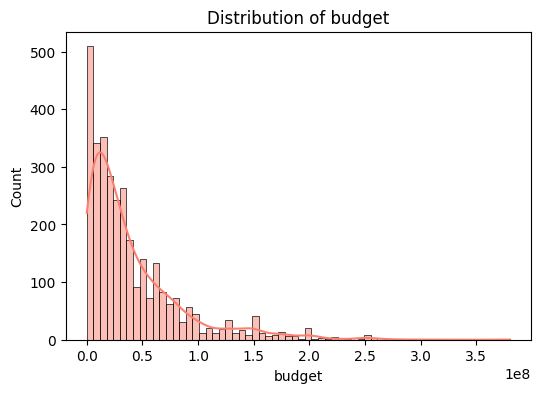

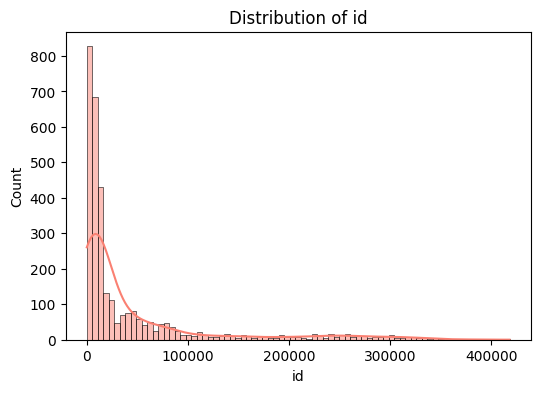

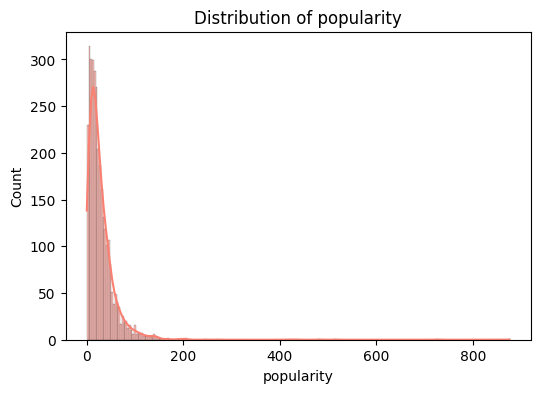

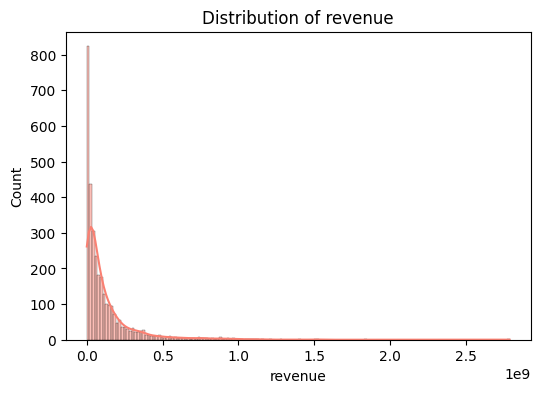

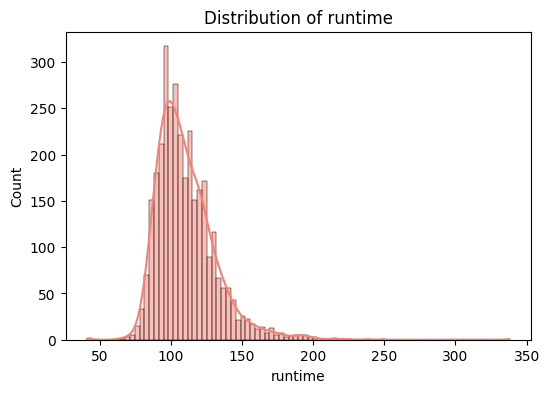

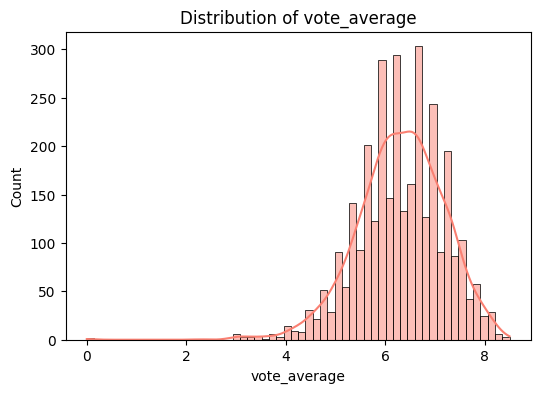

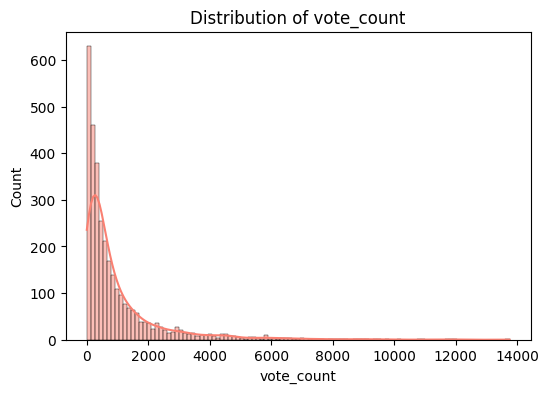

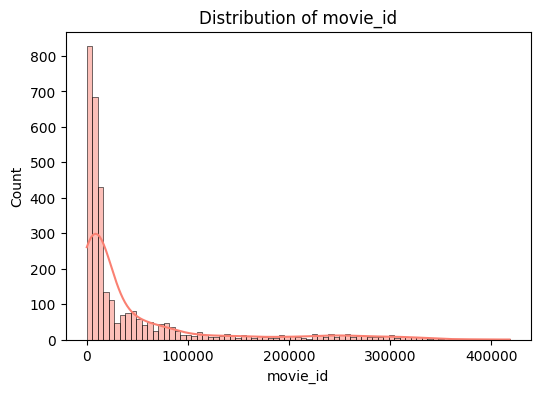

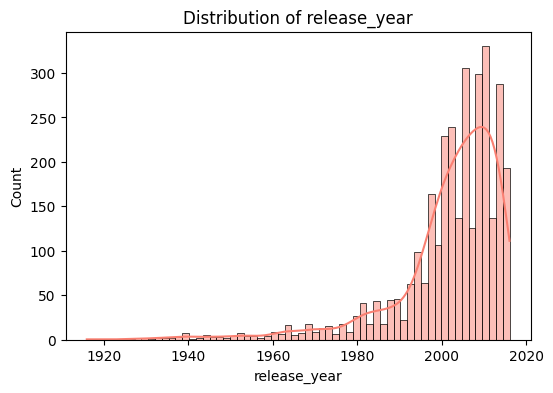

In [63]:
num_cols = df.select_dtypes(include=["number"]).columns

# Loop and generate an individual window for each plot
for col_name in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data=df, x=col_name, kde=True, color="salmon")
    plt.title(f"Distribution of {col_name}")
    plt.show()  # Displays each plot one after another

In [64]:
movies_missing = movies[(movies["budget"] == 0) | (movies["revenue"] == 0)]

In [65]:
movies_missing.describe().round(2)

,budget,id,popularity,release_date,revenue,runtime,vote_average,vote_count,movie_id,release_year
count,1.574000e+03,1574.00,1574.00,1573,1.574000e+03,1572.00,1574.00,1574.00,1574.00,1573.00
mean,5.228796e+06,82572.38,6.02,2004-07-28 12:04:07.171010688,2.289923e+06,98.97,5.65,101.31,82572.38,2004.09
min,0.000000e+00,20.00,0.00,1929-01-30 00:00:00,0.000000e+00,0.00,0.00,0.00,20.00,1929.00
25%,0.000000e+00,12245.50,1.19,2000-08-21 00:00:00,0.000000e+00,90.00,5.20,11.00,12245.50,2000.00
50%,0.000000e+00,28259.00,3.75,2006-05-12 00:00:00,0.000000e+00,98.00,5.90,38.00,28259.00,2006.00
75%,2.851995e+06,98504.00,8.48,2011-09-16 00:00:00,0.000000e+00,109.00,6.60,115.00,98504.00,2011.00
max,1.500000e+08,459488.00,74.82,2017-02-03 00:00:00,2.536254e+08,276.00,10.00,2067.00,459488.00,2017.00
std,1.316458e+07,107848.03,7.07,NaN,1.486928e+07,23.79,1.58,178.92,107848.03,10.23


In [66]:
for col in categorical:
    print(movies_missing[col].value_counts())

genres
[{"id": 18, "name": "Drama"}]                                                                           166
[{"id": 35, "name": "Comedy"}]                                                                           85
[{"id": 35, "name": "Comedy"}, {"id": 18, "name": "Drama"}]                                              72
[{"id": 18, "name": "Drama"}, {"id": 10749, "name": "Romance"}]                                          68
[{"id": 35, "name": "Comedy"}, {"id": 10749, "name": "Romance"}]                                         57
                                                                                                       ... 
[{"id": 878, "name": "Science Fiction"}, {"id": 53, "name": "Thriller"}]                                  1
[{"id": 53, "name": "Thriller"}, {"id": 27, "name": "Horror"}, {"id": 35, "name": "Comedy"}]              1
[{"id": 10769, "name": "Foreign"}, {"id": 53, "name": "Thriller"}]                                        1
[{"id": 99, "name": "

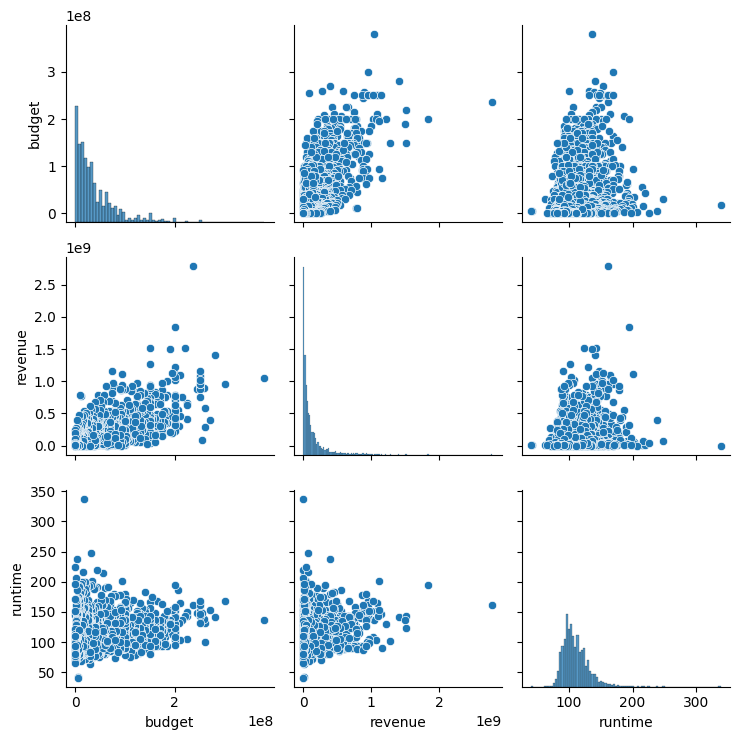

In [67]:
# Libraries for plotting
import matplotlib.pyplot as plt
import seaborn as sns

cols = ['budget','revenue','runtime'] # select attributes

sns.pairplot(df[cols],
             height=2.5)                      # plot pairwise relationships in a dataset
plt.tight_layout()                            # tight_layout automatically adjusts subplot params
                                              # so that the subplot(s) fits in to the figure area.
plt.show()

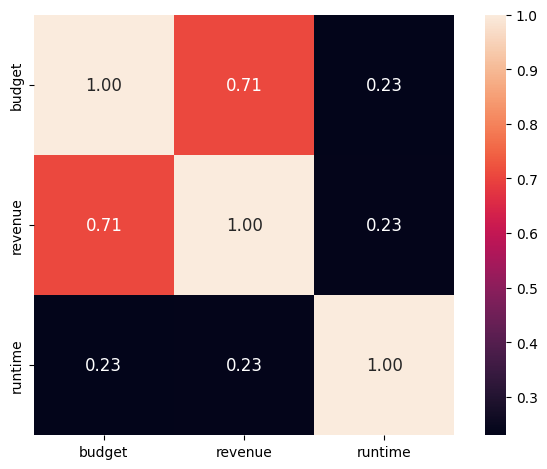

In [68]:
############################################ Correlations  ############################################

# Numpy is the fundamental package for scientific computing with Python
import numpy as np                  # np is an alias pointing to numpy


cm = np.corrcoef(df[cols].values.T) # returns Pearson product-moment correlation coefficients
                                    # input array_like: each row of x represents a variable, and each column a single observation of all those variables

# sns.set(font_scale=1.5)
# Heatmap visualisation of pearson correlation coefficients
# Documentation https://seaborn.pydata.org/generated/seaborn.heatmap.html
hm = sns.heatmap(cm,                # plot rectangular data as a color-encoded matrix
                 cbar=True,         # whether to draw a colorbar
                 annot=True,        # if True, write the data value in each cell
                 square=True,       # if True, set the Axes aspect to “equal” so each cell will be square-shaped
                 fmt='.2f',         # string formatting code to use when adding annotations
                 annot_kws={'size': 12}, # keyword arguments for ax.text when annot is True (size of font)
                 yticklabels=cols,  # if True, plot the column names of the dataframe.
                 xticklabels=cols)

plt.tight_layout()
# plt.savefig('correlation_coefficient.png', dpi=300) # Saves the figure in our local disk
plt.show()

# Data Prep

In [69]:
# Convert release_date from text into a date
df["release_date"] = pd.to_datetime(
    df["release_date"],
    errors="coerce"
)

# Extract year and month into new columns
df["release_year"] = df["release_date"].dt.year
df["release_month"] = df["release_date"].dt.month

# Extract genre names from the JSON text
df["genre_list"] = df["genres"].apply(
    lambda value: [
        genre["name"] for genre in json.loads(value)
    ]
)

display(
    df[
        ["title", "release_date", "release_year",
         "release_month", "genre_list"]
    ].head()
)

,title,release_date,release_year,release_month,genre_list
0,Avatar,2009-12-10,2009,12,"[Action, Adventure, Fantasy, Science Fiction]"
1,Pirates of the Caribbean: At World's End,2007-05-19,2007,5,"[Adventure, Fantasy, Action]"
2,Spectre,2015-10-26,2015,10,"[Action, Adventure, Crime]"
3,The Dark Knight Rises,2012-07-16,2012,7,"[Action, Crime, Drama, Thriller]"
4,John Carter,2012-03-07,2012,3,"[Action, Adventure, Science Fiction]"


In [70]:
# Compare old genres to genre_list
display(df[["title", "genres", "genre_list"]].head())

,title,genres,genre_list
0,Avatar,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[Action, Adventure, Fantasy, Science Fiction]"
1,Pirates of the Caribbean: At World's End,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...","[Adventure, Fantasy, Action]"
2,Spectre,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[Action, Adventure, Crime]"
3,The Dark Knight Rises,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...","[Action, Crime, Drama, Thriller]"
4,John Carter,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...","[Action, Adventure, Science Fiction]"


In [71]:
# Get the possible genre names from the original genre metadata
genre_names = sorted({
    genre["name"]
    for value in movies["genres"]
    for genre in json.loads(value)
})

# Create one binary column per genre
genre_columns = []

for genre in genre_names:
    column = "genre_" + genre.replace(" ", "_")
    genre_columns.append(column)

    df[column] = df["genre_list"].apply(
        lambda movie_genres: int(genre in movie_genres)
    )

# Preview the first five movies
display(df[["title", "genre_list"] + genre_columns].head())

,title,genre_list,genre_Action,genre_Adventure,genre_Animation,genre_Comedy,genre_Crime,genre_Documentary,genre_Drama,genre_Family,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science_Fiction,genre_TV_Movie,genre_Thriller,genre_War,genre_Western
0,Avatar,"[Action, Adventure, Fantasy, Science Fiction]",1,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,Pirates of the Caribbean: At World's End,"[Adventure, Fantasy, Action]",1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,Spectre,"[Action, Adventure, Crime]",1,1,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]",1,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,1,0,0
4,John Carter,"[Action, Adventure, Science Fiction]",1,1,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0


In [72]:
import ast

df['num_production_countries'] = df['production_countries'].apply(
    lambda x: len(ast.literal_eval(x)) if pd.notna(x) else 0
)

df['num_production_companies'] = df['production_companies'].apply(
    lambda x: len(ast.literal_eval(x)) if pd.notna(x) else 0
)

In [73]:


def get_lead_actor(value):
    if pd.isna(value):
        return None
    cast_list = json.loads(value)
    if not cast_list:
        return None
    # existing logic to find the lead (e.g., lowest "order") goes here
    lead = min(cast_list, key=lambda person: person["order"])
    return lead["id"]

def get_director(value):
    if pd.isna(value):
        return None
    crew_list = json.loads(value)
    for person in crew_list:
        if person.get("job") == "Director":
            return person["id"]
    return None
# def get_lead_actor(value):
#     cast = json.loads(value)
#     # The "order" field represents the position of the actor in the credits list
#     # order 0 being 1st billing or main star
#     if len(cast) == 0:
#         return None

#     # Lower cast order means earlier billing. Actor with order "0" will be closest to beginning of the cast list. This is the first-billed actor
#     lead = min(cast, key=lambda person: person["order"])
#     return lead["id"]


# def get_director(value):
#     crew = json.loads(value)

#     directors = [
#         person for person in crew
#         if person["job"] == "Director"
#     ]

#     if len(directors) == 0:
#         return None

#     # For the initial model, use the first listed director
#     return directors[0]["id"]


df["lead_actor_id"] = df["cast"].apply(get_lead_actor)
df["director_id"] = df["crew"].apply(get_director)

In [74]:
def get_lead_actor_name(value):
    if pd.isna(value):
        return None
    cast_list = json.loads(value)
    if not cast_list:
        return None
    lead = min(cast_list, key=lambda person: person["order"])
    return lead["name"]

def get_director_name(value):
    if pd.isna(value):
        return None
    crew_list = json.loads(value)
    for person in crew_list:
        if person.get("job") == "Director":
            return person["name"]
    return None

# def get_lead_actor_name(value):
#     cast = json.loads(value)

#     if len(cast) == 0:
#         return None

#     return min(cast, key=lambda person: person["order"])["name"]


# def get_director_name(value):
#     directors = [
#         person for person in json.loads(value)
#         if person["job"] == "Director"
#     ]

#     return directors[0]["name"] if directors else None


df["lead_actor_name"] = df["cast"].apply(get_lead_actor_name)
df["director_name"] = df["crew"].apply(get_director_name)

display(
    df[
        ["title", "release_date",
         "lead_actor_name", "director_name"]
    ].head()
)

print("Missing lead actors:", df["lead_actor_id"].isna().sum())
print("Missing directors:", df["director_id"].isna().sum())

,title,release_date,lead_actor_name,director_name
0,Avatar,2009-12-10,Sam Worthington,James Cameron
1,Pirates of the Caribbean: At World's End,2007-05-19,Johnny Depp,Gore Verbinski
2,Spectre,2015-10-26,Daniel Craig,Sam Mendes
3,The Dark Knight Rises,2012-07-16,Christian Bale,Christopher Nolan
4,John Carter,2012-03-07,Taylor Kitsch,Andrew Stanton


Missing lead actors: 2
Missing directors: 2


### Split for training

In [75]:
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# sort by release date
dated_df = df.dropna(subset=["release_date"])
dated_df = dated_df.sort_values(["release_date", "id"]).reset_index(drop=True)
dated_df["log_budget"] = np.log1p(dated_df["budget"]) # reducing the skew caused by extreme production budgets.
# dated_df["runtime"] = dated_df["runtime"].replace(0, np.nan)

# first 80% of movies = train, last 20% = test
split_position = int(len(dated_df) * 0.8)
cutoff_date = dated_df.iloc[split_position]["release_date"]
train_df = dated_df[dated_df["release_date"] < cutoff_date].copy()
test_df = dated_df[dated_df["release_date"] >= cutoff_date].copy()

# 5 time series folds, split by date so movies from the same day stay together
training_dates = np.sort(train_df["release_date"].unique())
cv = []
for train_idx, val_idx in TimeSeriesSplit(n_splits=5).split(training_dates):
    train_rows = np.where(train_df["release_date"].isin(training_dates[train_idx]))[0]
    val_rows = np.where(train_df["release_date"].isin(training_dates[val_idx]))[0]
    cv.append((train_rows, val_rows))

print("Cutoff date:", cutoff_date.date())
print("Train:", len(train_df), " Test:", len(test_df))

Cutoff date: 2011-11-02
Train: 2583  Test: 646


### Build an actor-history table from training films only

In [76]:
# Extract all actor IDs from each training movie
actor_history = train_df[
    ["id", "release_date", "revenue", "cast"]
].copy()

actor_history["actor_id"] = actor_history["cast"].apply(
    lambda value: [
        person["id"] for person in json.loads(value)
    ]
)

# Create one row per movie–actor combination
actor_history = actor_history.explode("actor_id")

actor_history = (
    actor_history
    .dropna(subset=["actor_id"])
    .drop_duplicates(subset=["id", "actor_id"])
)

display(
    actor_history[
        ["id", "release_date", "revenue", "actor_id"]
    ].head()
)

,id,release_date,revenue,actor_id
0,3059,1916-09-04,8394751,8828
0,3059,1916-09-04,8394751,8829
0,3059,1916-09-04,8394751,29950
0,3059,1916-09-04,8394751,29951
0,3059,1916-09-04,8394751,29952


### Create a function to look up earlier performance

In [77]:
# Group historical appearances by actor for easy lookup
actor_groups = {
    actor_id: group
    for actor_id, group in actor_history.groupby("actor_id")
}

def get_prior_actor_stats(row):
    history = actor_groups.get(row["lead_actor_id"])

    if history is None:
        return pd.Series([np.nan, 0])

    # Strictly earlier dates exclude the current movie
    # and other movies released on the same date
    earlier = history.loc[
        history["release_date"] < row["release_date"],
        "revenue"
    ]

    return pd.Series([
        earlier.median(),
        len(earlier)
    ])

### Apply it to training and test movies

In [78]:
history_columns = [
    "lead_actor_prior_median_gross",
    "lead_actor_prior_film_count"
]

train_df[history_columns] = train_df.apply(
    get_prior_actor_stats, axis=1
)

test_df[history_columns] = test_df.apply(
    get_prior_actor_stats, axis=1
)

display(
    train_df[
        ["title", "release_date", "lead_actor_name"]
        + history_columns
    ].tail(10)
)

print(
    "Training movies without observed actor history:",
    train_df["lead_actor_prior_median_gross"].isna().sum()
)

print(
    "Test movies without observed actor history:",
    test_df["lead_actor_prior_median_gross"].isna().sum()
)

,title,release_date,lead_actor_name,lead_actor_prior_median_gross,lead_actor_prior_film_count
2573,Courageous,2011-09-30,Alex Kendrick,10178331.0,1.0
2574,Shame,2011-10-02,Michael Fassbender,27462041.0,7.0
2575,The Big Year,2011-10-13,Owen Wilson,91753202.0,29.0
2576,My Week with Marilyn,2011-10-17,Michelle Williams,27500000.0,7.0
2577,Paranormal Activity 3,2011-10-19,Katie Featherston,185433916.0,2.0
2578,Anonymous,2011-10-21,Jamie Campbell Bower,25739015.0,3.0
2579,The Adventures of Tintin,2011-10-25,Jamie Bell,166115593.0,4.0
2580,In Time,2011-10-27,Justin Timberlake,176033953.0,8.0
2581,Like Crazy,2011-10-28,Anton Yelchin,80769270.5,8.0
2582,Puss in Boots,2011-10-28,Antonio Banderas,98185582.0,23.0


Training movies without observed actor history: 462
Test movies without observed actor history: 80


## Same for director

In [79]:
### Build the director-history table

director_history = train_df[
    ["id", "release_date", "revenue", "crew"]
].copy()

# Find everyone credited as a director
director_history["director_id"] = director_history["crew"].apply(
    lambda value: [
        person["id"]
        for person in json.loads(value)
        if person["job"] == "Director"
    ]
)

# One row per movie–director combination
director_history = director_history.explode("director_id")

director_history = (
    director_history
    .dropna(subset=["director_id"])
    .drop_duplicates(subset=["id", "director_id"])
)

director_groups = {
    director_id: group
    for director_id, group
    in director_history.groupby("director_id")
}

In [80]:
# Look up earlier films
def get_prior_director_stats(row):
    history = director_groups.get(row["director_id"])

    if history is None:
        return pd.Series([np.nan, 0])

    earlier = history.loc[
        history["release_date"] < row["release_date"],
        "revenue"
    ]

    return pd.Series([
        earlier.median(),
        len(earlier)
    ])

In [81]:
##Add the features to both datasets

director_columns = [
    "director_prior_median_gross",
    "director_prior_film_count"
]

train_df[director_columns] = train_df.apply(
    get_prior_director_stats, axis=1
)

test_df[director_columns] = test_df.apply(
    get_prior_director_stats, axis=1
)

display(
    train_df[
        ["title", "release_date", "director_name"]
        + director_columns
    ].tail(10)
)

print(
    "Training movies without observed director history:",
    train_df["director_prior_median_gross"].isna().sum()
)

print(
    "Test movies without observed director history:",
    test_df["director_prior_median_gross"].isna().sum()
)

,title,release_date,director_name,director_prior_median_gross,director_prior_film_count
2573,Courageous,2011-09-30,Alex Kendrick,21817324.0,2.0
2574,Shame,2011-10-02,Steve McQueen,NaN,0.0
2575,The Big Year,2011-10-13,David Frankel,285316735.0,2.0
2576,My Week with Marilyn,2011-10-17,Simon Curtis,NaN,0.0
2577,Paranormal Activity 3,2011-10-19,Henry Joost,NaN,0.0
2578,Anonymous,2011-10-21,Roland Emmerich,656962998.5,4.0
2579,The Adventures of Tintin,2011-10-25,Steven Spielberg,327182783.5,22.0
2580,In Time,2011-10-27,Andrew Niccol,18330336.0,2.0
2581,Like Crazy,2011-10-28,Drake Doremus,NaN,0.0
2582,Puss in Boots,2011-10-28,Chris Miller,798958165.0,1.0


Training movies without observed director history: 1200
Test movies without observed director history: 248


### Add Production country and company indicators

In [82]:
def add_top_n_indicators(train, test, source_column, prefix, n=10):
    train_lists = train[source_column].apply(
        lambda value: [item["name"] for item in json.loads(value)]
    )
    test_lists = test[source_column].apply(
        lambda value: [item["name"] for item in json.loads(value)]
    )

    # Rank categories by frequency in TRAINING data only
    from collections import Counter
    counts = Counter(name for names in train_lists for name in names)
    top_categories = [name for name, _ in counts.most_common(n)]

    new_columns = []
    for category in top_categories:
        column = prefix + category.replace(" ", "_")
        new_columns.append(column)

        train[column] = train_lists.apply(lambda names: int(category in names))
        test[column] = test_lists.apply(lambda names: int(category in names))

    return new_columns


country_columns = add_top_n_indicators(
    train_df, test_df, "production_countries", "country_", n=10
)

production_columns = add_top_n_indicators(
    train_df, test_df, "production_companies", "company_", n=10
)

display(
    train_df[
        ["title"] + country_columns + production_columns
    ].head()
)

,title,country_United_States_of_America,country_United_Kingdom,country_Germany,country_France,country_Canada,country_Australia,country_Italy,country_Japan,country_Spain,...,company_Warner_Bros.,company_Universal_Pictures,company_Paramount_Pictures,company_Twentieth_Century_Fox_Film_Corporation,company_Columbia_Pictures,company_New_Line_Cinema,company_Touchstone_Pictures,company_Columbia_Pictures_Corporation,company_Walt_Disney_Pictures,company_Metro-Goldwyn-Mayer_(MGM)
0,Intolerance,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,The Big Parade,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
2,Metropolis,0,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,The Broadway Melody,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4,Hell's Angels,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


###  Select final predictors and target; exclude leakage fields

In [83]:
numeric_features = [
    "budget",
    "release_year",
    "lead_actor_prior_median_gross",
    "lead_actor_prior_film_count",
    "director_prior_median_gross",
    "director_prior_film_count"
]

categorical_features = [
    "release_month"
]

# genre_columns was created in the genre-encoding step
feature_columns = (
    numeric_features
    + categorical_features
    + genre_columns
    + production_columns
    + country_columns
)

X_train = train_df[feature_columns].copy()
y_train = train_df["revenue"].copy()

X_test = test_df[feature_columns].copy()
y_test = test_df["revenue"].copy()

print("Training predictors:", X_train.shape)
print("Test predictors:", X_test.shape)

display(X_train.head())

Training predictors: (2583, 47)
Test predictors: (646, 47)


,budget,release_year,lead_actor_prior_median_gross,lead_actor_prior_film_count,director_prior_median_gross,director_prior_film_count,release_month,genre_Action,genre_Adventure,genre_Animation,...,country_United_States_of_America,country_United_Kingdom,country_Germany,country_France,country_Canada,country_Australia,country_Italy,country_Japan,country_Spain,country_Ireland
0,385907,1916,NaN,0.0,NaN,0.0,9,0,0,0,...,1,0,0,0,0,0,0,0,0,0
1,245000,1925,NaN,0.0,NaN,0.0,11,0,0,0,...,1,0,0,0,0,0,0,0,0,0
2,92620000,1927,NaN,0.0,NaN,0.0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,379000,1929,NaN,0.0,NaN,0.0,2,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,3950000,1930,NaN,0.0,NaN,0.0,11,1,0,0,...,1,0,0,0,0,0,0,0,0,0


In [84]:
X_train.columns

Index(['budget', 'release_year', 'lead_actor_prior_median_gross',
       'lead_actor_prior_film_count', 'director_prior_median_gross',
       'director_prior_film_count', 'release_month', 'genre_Action',
       'genre_Adventure', 'genre_Animation', 'genre_Comedy', 'genre_Crime',
       'genre_Documentary', 'genre_Drama', 'genre_Family', 'genre_Fantasy',
       'genre_Foreign', 'genre_History', 'genre_Horror', 'genre_Music',
       'genre_Mystery', 'genre_Romance', 'genre_Science_Fiction',
       'genre_TV_Movie', 'genre_Thriller', 'genre_War', 'genre_Western',
       'company_Warner_Bros.', 'company_Universal_Pictures',
       'company_Paramount_Pictures',
       'company_Twentieth_Century_Fox_Film_Corporation',
       'company_Columbia_Pictures', 'company_New_Line_Cinema',
       'company_Touchstone_Pictures', 'company_Columbia_Pictures_Corporation',
       'company_Walt_Disney_Pictures', 'company_Metro-Goldwyn-Mayer_(MGM)',
       'country_United_States_of_America', 'country_United_K

## See if revenue history is missing

In [85]:
# Actor history: 1 means missing; 0 means available
X_train["actor_history_missing"] = (
    X_train["lead_actor_prior_median_gross"].isna().astype(int)
)

X_test["actor_history_missing"] = (
    X_test["lead_actor_prior_median_gross"].isna().astype(int)
)

# Director history: 1 means missing; 0 means available
X_train["director_history_missing"] = (
    X_train["director_prior_median_gross"].isna().astype(int)
)

X_test["director_history_missing"] = (
    X_test["director_prior_median_gross"].isna().astype(int)
)

In [86]:
display(
    X_train[
        [
            "lead_actor_prior_median_gross",
            "actor_history_missing",
            "director_prior_median_gross",
            "director_history_missing"
        ]
    ].head(10)
)

,lead_actor_prior_median_gross,actor_history_missing,director_prior_median_gross,director_history_missing
0,NaN,1,NaN,1
1,NaN,1,NaN,1
2,NaN,1,NaN,1
3,NaN,1,NaN,1
4,NaN,1,NaN,1
5,NaN,1,NaN,1
6,NaN,1,NaN,1
7,NaN,1,NaN,1
8,NaN,1,NaN,1
9,NaN,1,NaN,1


In [87]:

##Check for latest training
display(
    X_train[
        [
            "lead_actor_prior_median_gross",
            "actor_history_missing",
            "director_prior_median_gross",
            "director_history_missing"
        ]
    ].tail(10)
)

,lead_actor_prior_median_gross,actor_history_missing,director_prior_median_gross,director_history_missing
2573,10178331.0,0,21817324.0,0
2574,27462041.0,0,NaN,1
2575,91753202.0,0,285316735.0,0
2576,27500000.0,0,NaN,1
2577,185433916.0,0,NaN,1
2578,25739015.0,0,656962998.5,0
2579,166115593.0,0,327182783.5,0
2580,176033953.0,0,18330336.0,0
2581,80769270.5,0,NaN,1
2582,98185582.0,0,798958165.0,0


In [88]:
## Just to check how many have history

print(
    "Movies with actor history:",
    X_train["lead_actor_prior_median_gross"].notna().sum()
)

print(
    "Movies with director history:",
    X_train["director_prior_median_gross"].notna().sum()
)

Movies with actor history: 2121
Movies with director history: 1383


## Define what to do with missing value, transform

In [89]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical predictors: fill missing values, then standardize
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        keep_empty_features=True
    ))
])

# Categorical predictors: fill missing values, then encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the three types of predictors
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

## Inspecting Final Predictors

In [90]:
X_train[numeric_features].describe()

,budget,release_year,lead_actor_prior_median_gross,lead_actor_prior_film_count,director_prior_median_gross,director_prior_film_count
count,2.583000e+03,2583.000000,2.121000e+03,2583.000000,1.383000e+03,2583.000000
mean,3.741293e+07,1998.695316,1.041044e+08,6.145567,1.145323e+08,1.548587
std,3.978305e+07,13.244457,9.369577e+07,6.268868,1.292118e+08,2.413785
min,1.000000e+00,1916.000000,2.500000e+01,0.000000,1.000000e+04,0.000000
25%,1.000000e+07,1996.000000,4.401737e+07,1.000000,3.000000e+07,0.000000
50%,2.500000e+07,2002.000000,8.481171e+07,4.000000,7.090697e+07,1.000000
75%,5.000000e+07,2007.000000,1.367661e+08,9.000000,1.500831e+08,2.000000
max,3.800000e+08,2011.000000,1.014323e+09,37.000000,9.382127e+08,22.000000


In [91]:
for col in categorical_features:
    print(X_train[col].value_counts())

release_month
9     316
12    269
10    242
6     236
8     231
7     209
11    204
5     200
3     189
2     174
4     173
1     140
Name: count, dtype: int64


In [92]:

genre_counts = X_train[genre_columns].sum().sort_values(ascending=False)
print(genre_counts)

genre_Drama              1162
genre_Comedy              911
genre_Thriller            758
genre_Action              726
genre_Adventure           524
genre_Romance             496
genre_Crime               426
genre_Science_Fiction     343
genre_Family              294
genre_Fantasy             273
genre_Horror              268
genre_Mystery             229
genre_Animation           138
genre_History             116
genre_War                 102
genre_Music                90
genre_Western              51
genre_Documentary          33
genre_Foreign               4
genre_TV_Movie              0
dtype: int64


In [93]:
production_counts = X_train[production_columns].sum().sort_values(ascending=False)
print(production_counts)

company_Warner_Bros.                              234
company_Universal_Pictures                        222
company_Paramount_Pictures                        205
company_Twentieth_Century_Fox_Film_Corporation    168
company_Columbia_Pictures                         126
company_New_Line_Cinema                           113
company_Touchstone_Pictures                        89
company_Columbia_Pictures_Corporation              86
company_Walt_Disney_Pictures                       74
company_Metro-Goldwyn-Mayer_(MGM)                  73
dtype: int64


In [94]:
country_counts = X_train[country_columns].sum().sort_values(ascending=False)
print(country_counts)

country_United_States_of_America    2328
country_United_Kingdom               354
country_Germany                      218
country_France                       150
country_Canada                       129
country_Australia                     62
country_Italy                         45
country_Japan                         35
country_Spain                         30
country_Ireland                       20
dtype: int64


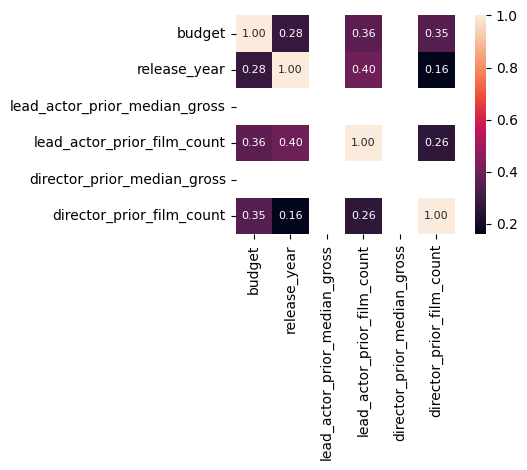

In [95]:
############################################ Correlations  ############################################

# Numpy is the fundamental package for scientific computing with Python
import numpy as np                  # np is an alias pointing to numpy


cm = np.corrcoef(X_train[numeric_features].values.T) # returns Pearson product-moment correlation coefficients
                                    # input array_like: each row of x represents a variable, and each column a single observation of all those variables

# sns.set(font_scale=1.5)
# Heatmap visualisation of pearson correlation coefficients
# Documentation https://seaborn.pydata.org/generated/seaborn.heatmap.html
hm = sns.heatmap(cm,                # plot rectangular data as a color-encoded matrix
                 cbar=True,         # whether to draw a colorbar
                 annot=True,        # if True, write the data value in each cell
                 square=True,       # if True, set the Axes aspect to “equal” so each cell will be square-shaped
                 fmt='.2f',         # string formatting code to use when adding annotations
                 annot_kws={'size': 8}, # keyword arguments for ax.text when annot is True (size of font)
                 yticklabels=numeric_features,  # if True, plot the column names of the dataframe.
                 xticklabels=numeric_features)

plt.tight_layout()
# plt.savefig('correlation_coefficient.png', dpi=300) # Saves the figure in our local disk
plt.show()

# Modeling

In [96]:
# transformations
X_train_tran = X_train.copy()
X_train_tran['log_budget'] = np.log1p(X_train['budget'])

X_test_tran = X_test.copy()
X_test_tran['log_budget'] = np.log1p(X_test['budget'])

## Linear Regression

In [97]:
def make_preprocessor(numeric_columns, include_genres=False, include_month=False,
                       include_country=False, include_production=False):
    """Select features and prepare them within each training fold."""
    numeric_pipeline = Pipeline([
        # Use the training median to fill missing numeric values.
        ('imputer', SimpleImputer(strategy='median')),
        # Put numbers on comparable scales for KNN distances.
        ('scaler', StandardScaler())
    ])
    transformers = [('numeric', numeric_pipeline, numeric_columns)]
    if include_genres:
        # Genres are already binary indicators.
        transformers.append(('genres', 'passthrough', genre_columns))
    if include_month:
        # Months are categories, not an ordered numeric distance.
        month_pipeline = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ])
        transformers.append(('month', month_pipeline, ['release_month']))
    if include_country:
        # Country indicators are already binary (top-N, learned from training only).
        transformers.append(('country', 'passthrough', country_columns))
    if include_production:
        # Production company indicators are already binary (top-N, learned from training only).
        transformers.append(('production', 'passthrough', production_columns))
    # Ignore every column not selected above.
    return ColumnTransformer(transformers, remainder='drop')

In [98]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

from sklearn.preprocessing import StandardScaler # standardize features by removing the mean and scaling to unit variance
                                                 # the standard score of a sample x is calculated as: z = (x - u) / s
                                                 # where u is the mean of the training sample , and s is the standard deviation of the training sample.
                                                 # centering and scaling happens independently on each feature.
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from  warnings import simplefilter
from sklearn.exceptions import ConvergenceWarning
simplefilter("ignore", category=ConvergenceWarning)
# from scipy.linalg import LinAlgWarning
# simplefilter('ignore', category=LinAlgWarning)
from sklearn.model_selection import GridSearchCV
ridge_parameters = {
    'model__alpha': [0.1, 1, 10, 100, 1000, 10000, 100000]
}

# Full numeric feature set, using log_budget in place of raw budget
full_numeric_columns = [
    'log_budget',
    'lead_actor_prior_median_gross',
    'lead_actor_prior_film_count',
    'director_prior_median_gross',
    'director_prior_film_count'
]

linear_candidates = [
    ('Ridge: all numeric', full_numeric_columns, False, False, False, False),
    ('Ridge: all numeric + month', full_numeric_columns, False, True, False, False),
    ('Ridge: all numeric + genres', full_numeric_columns, True, False, False, False),
    ('Ridge: all numeric + country', full_numeric_columns, False, False, True, False),
    ('Ridge: all numeric + production', full_numeric_columns, False, False, False, True),
    ('Ridge: all numeric + country + production', full_numeric_columns, False, False, True, True),
    ('Ridge: all numeric + genres + month + country + production', full_numeric_columns, True, True, True, True),
]

ridge_searches = {}
cv_results = []

for name, numeric_columns, include_genres, include_month, include_country, include_production in linear_candidates:
    estimator = Ridge(random_state=42)
    parameters = ridge_parameters

    pipeline = Pipeline([
        ('prep', make_preprocessor(numeric_columns, include_genres, include_month,
                                    include_country, include_production)),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipeline, parameters,
        scoring='neg_root_mean_squared_error',
        cv=cv, n_jobs=-1
    )
    print('Fitting:', name)
    search.fit(X_train_tran, y_train)
    ridge_searches[name] = search
    cv_results.append({
        'Candidate': name,
        'CV RMSE': -search.best_score_,
        'Best settings': search.best_params_
    })

ridge_cv_table = pd.DataFrame(cv_results).sort_values('CV RMSE').reset_index(drop=True)
display(ridge_cv_table[['Candidate', 'CV RMSE']])

Fitting: Ridge: all numeric
Fitting: Ridge: all numeric + month
Fitting: Ridge: all numeric + genres
Fitting: Ridge: all numeric + country
Fitting: Ridge: all numeric + production
Fitting: Ridge: all numeric + country + production
Fitting: Ridge: all numeric + genres + month + country + production


,Candidate,CV RMSE
0,Ridge: all numeric + genres + month + country ...,1.423501e+08
1,Ridge: all numeric + genres,1.453528e+08
2,Ridge: all numeric + month,1.467565e+08
3,Ridge: all numeric + country + production,1.474536e+08
4,Ridge: all numeric + production,1.481126e+08
5,Ridge: all numeric + country,1.487389e+08
6,Ridge: all numeric,1.495098e+08


In [99]:
##################################### Ridge - Fit and Evaluate Model #####################################
#Fit and Evaluate Model

best_ridge_name = ridge_cv_table.iloc[0]['Candidate']
best_ridge_search = ridge_searches[best_ridge_name]
# The selected model has already been fitted on all training movies.
ridge_prediction = best_ridge_search.best_estimator_.predict(X_test_tran)

# Predict average training revenue for every test movie as a benchmark.
ridge_baseline = DummyRegressor(strategy='mean')
ridge_baseline.fit(X_train_tran, y_train)
ridge_baseline_prediction = ridge_baseline.predict(X_test_tran)

ridge_results = []
for name, prediction in [
    ('Mean baseline', ridge_baseline_prediction),
    (best_ridge_name, ridge_prediction)
]:
    ridge_results.append({
        'Model': name,
        # RMSE gives extra weight to large dollar errors.
        'Test RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        # MAE is the average absolute dollar error.
        'Test MAE': mean_absolute_error(y_test, prediction),
        # R² compares predictions with the test-mean reference. Higher is better.
        'Test R²': r2_score(y_test, prediction)
    })
ridge_results = pd.DataFrame(ridge_results)
display(ridge_results)

# A second table uses millions of dollars for presentation readability.
presentation_results = ridge_results.rename(columns={
    'Test RMSE': 'Test RMSE ($M)', 'Test MAE': 'Test MAE ($M)'
}).copy()
presentation_results[['Test RMSE ($M)', 'Test MAE ($M)']] /= 1_000_000
display(presentation_results.round(3))

,Model,Test RMSE,Test MAE,Test R²
0,Mean baseline,2.526444e+08,1.437628e+08,-0.070414
1,Ridge: all numeric + genres + month + country ...,2.040505e+08,1.137749e+08,0.301755


,Model,Test RMSE ($M),Test MAE ($M),Test R²
0,Mean baseline,252.644,143.763,-0.070
1,Ridge: all numeric + genres + month + country ...,204.051,113.775,0.302


In [100]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

from sklearn.preprocessing import StandardScaler # standardize features by removing the mean and scaling to unit variance
                                                 # the standard score of a sample x is calculated as: z = (x - u) / s
                                                 # where u is the mean of the training sample , and s is the standard deviation of the training sample.
                                                 # centering and scaling happens independently on each feature.
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from  warnings import simplefilter
from sklearn.exceptions import ConvergenceWarning
simplefilter("ignore", category=ConvergenceWarning)
# from scipy.linalg import LinAlgWarning
# simplefilter('ignore', category=LinAlgWarning)
from sklearn.model_selection import GridSearchCV
lasso_parameters = {
    'model__alpha': [0.1, 1, 10, 100, 1000, 10000, 100000]
}

# Full numeric feature set, using log_budget in place of raw budget
full_numeric_columns = [
    'log_budget',
    'lead_actor_prior_median_gross',
    'lead_actor_prior_film_count',
    'director_prior_median_gross',
    'director_prior_film_count'
]

linear_candidates = [
    ('lasso: all numeric', full_numeric_columns, False, False, False, False),
    ('lasso: all numeric + month', full_numeric_columns, False, True, False, False),
    ('lasso: all numeric + genres', full_numeric_columns, True, False, False, False),
    ('lasso: all numeric + country', full_numeric_columns, False, False, True, False),
    ('lasso: all numeric + production', full_numeric_columns, False, False, False, True),
    ('lasso: all numeric + country + production', full_numeric_columns, False, False, True, True),
    ('lasso: all numeric + genres + month + country + production', full_numeric_columns, True, True, True, True),
]

lasso_searches = {}
cv_results = []

for name, numeric_columns, include_genres, include_month, include_country, include_production in linear_candidates:
    estimator = Lasso(random_state=42)
    parameters = lasso_parameters

    pipeline = Pipeline([
        ('prep', make_preprocessor(numeric_columns, include_genres, include_month,
                                    include_country, include_production)),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipeline, parameters,
        scoring='neg_root_mean_squared_error',
        cv=cv, n_jobs=-1
    )
    print('Fitting:', name)
    search.fit(X_train_tran, y_train)
    lasso_searches[name] = search
    cv_results.append({
        'Candidate': name,
        'CV RMSE': -search.best_score_,
        'Best settings': search.best_params_
    })

lasso_cv_table = pd.DataFrame(cv_results).sort_values('CV RMSE').reset_index(drop=True)
display(lasso_cv_table[['Candidate', 'CV RMSE']])

Fitting: lasso: all numeric
Fitting: lasso: all numeric + month
Fitting: lasso: all numeric + genres
Fitting: lasso: all numeric + country
Fitting: lasso: all numeric + production
Fitting: lasso: all numeric + country + production
Fitting: lasso: all numeric + genres + month + country + production


,Candidate,CV RMSE
0,lasso: all numeric + genres + month + country ...,1.435164e+08
1,lasso: all numeric + genres,1.457613e+08
2,lasso: all numeric + month,1.467483e+08
3,lasso: all numeric + country + production,1.478245e+08
4,lasso: all numeric + production,1.483840e+08
5,lasso: all numeric + country,1.487395e+08
6,lasso: all numeric,1.495057e+08


##  kNN

In [101]:
knn_parameters = {
    'model__n_neighbors': [5, 15, 30, 60],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]  # 1 = Manhattan; 2 = Euclidean distance
}

# Each row specifies a model family and the features to include.
# The same loop fits all candidates, avoiding duplicate model code.
knn_candidates = [
    # Original baseline comparisons, kept as-is for reference
    ('KNN: log budget + month', 'KNN', ['log_budget'], False, True, False, False),
    ('KNN: log budget + genres', 'KNN', ['log_budget'], True, False, False, False),
    ('KNN: log budget + genres + month', 'KNN', ['log_budget'], True, True, False, False),
    ('KNN: raw budget', 'KNN', ['budget'], False, False, False, False),
    ('KNN: log budget', 'KNN', ['log_budget'], False, False, False, False),

    # New: all numeric features
    ('KNN: all numeric', 'KNN', full_numeric_columns, False, False, False, False),
    ('KNN: all numeric + genres', 'KNN', full_numeric_columns, True, False, False, False),
    ('KNN: all numeric + country', 'KNN', full_numeric_columns, False, False, True, False),
    ('KNN: all numeric + production', 'KNN', full_numeric_columns, False, False, False, True),
    ('KNN: all numeric + country + production', 'KNN', full_numeric_columns, False, False, True, True),
    ('KNN: all numeric + genres + country + production', 'KNN', full_numeric_columns, True, False, True, True),
]

knn_searches = {}
knn_cv_results = []

for name, family, numeric_columns, genres, month, countries, productions in knn_candidates:
    estimator = KNeighborsRegressor()
    parameters = knn_parameters

    pipeline = Pipeline([
        ('prep', make_preprocessor(numeric_columns, genres, month, countries, productions)),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipeline, parameters,
        scoring='neg_root_mean_squared_error',
        cv=cv, n_jobs=-1
    )
    print('Fitting:', name)
    search.fit(X_train_tran, y_train)
    knn_searches[name] = search
    knn_cv_results.append({
        'Candidate': name,
        'CV RMSE': -search.best_score_,
        'Best settings': search.best_params_
    })

knn_cv_table = pd.DataFrame(knn_cv_results).sort_values('CV RMSE').reset_index(drop=True)
display(knn_cv_table[['Candidate', 'CV RMSE']])

# Choose one winner from each family using CV only.
selected_knn_name = max(
    knn_searches,
    key=lambda name: knn_searches[name].best_score_
)
print('Selected:', selected_knn_name)
print('Settings:', knn_searches[selected_knn_name].best_params_)

best_knn_model = knn_searches[selected_knn_name].best_estimator_

Fitting: KNN: log budget + month
Fitting: KNN: log budget + genres
Fitting: KNN: log budget + genres + month
Fitting: KNN: raw budget
Fitting: KNN: log budget
Fitting: KNN: all numeric
Fitting: KNN: all numeric + genres
Fitting: KNN: all numeric + country
Fitting: KNN: all numeric + production
Fitting: KNN: all numeric + country + production
Fitting: KNN: all numeric + genres + country + production


,Candidate,CV RMSE
0,KNN: raw budget,1.360493e+08
1,KNN: log budget,1.363770e+08
2,KNN: log budget + genres + month,1.380368e+08
3,KNN: log budget + month,1.411202e+08
4,KNN: all numeric + genres + country + production,1.431048e+08
5,KNN: log budget + genres,1.446615e+08
6,KNN: all numeric + genres,1.450062e+08
7,KNN: all numeric + country + production,1.493619e+08
8,KNN: all numeric,1.496385e+08
9,KNN: all numeric + production,1.497351e+08


Selected: KNN: raw budget
Settings: {'model__n_neighbors': 30, 'model__p': 1, 'model__weights': 'uniform'}


## Decision Tree Regressor

In [102]:
tree_parameters = {
    'model__max_depth': [3, 5, 8, None],
    'model__min_samples_leaf': [5, 20, 50]
}

# Each row specifies a model family and the features to include.
# The same loop fits all candidates, avoiding duplicate model code.
tree_candidates = [
    ('Tree: log budget + genres', 'Tree', ['log_budget'], True, False, False, False),
    ('Tree: log budget + genres + month', 'Tree', ['log_budget'], True, True, False, False),

    # New: all numeric features
    ('Tree: all numeric', 'Tree', full_numeric_columns, False, False, False, False),
    ('Tree: all numeric + genres', 'Tree', full_numeric_columns, True, False, False, False),
    ('Tree: all numeric + country', 'Tree', full_numeric_columns, False, False, True, False),
    ('Tree: all numeric + production', 'Tree', full_numeric_columns, False, False, False, True),
    ('Tree: all numeric + country + production', 'Tree', full_numeric_columns, False, False, True, True),
    ('Tree: all numeric + genres + country + production', 'Tree', full_numeric_columns, True, False, True, True),
]

tree_searches = {}
tree_cv_results = []

for name, family, numeric_columns, genres, month, countries, productions in tree_candidates:
    estimator = DecisionTreeRegressor(random_state=42)
    parameters = tree_parameters

    pipeline = Pipeline([
        ('prep', make_preprocessor(numeric_columns, genres, month, countries, productions)),
        ('model', estimator)
    ])
    search = GridSearchCV(
        pipeline, parameters,
        scoring='neg_root_mean_squared_error',
        cv=cv, n_jobs=-1
    )
    print('Fitting:', name)
    search.fit(X_train_tran, y_train)
    tree_searches[name] = search
    tree_cv_results.append({
        'Candidate': name,
        'CV RMSE': -search.best_score_,
        'Best settings': search.best_params_
    })

tree_cv_table = pd.DataFrame(tree_cv_results).sort_values('CV RMSE').reset_index(drop=True)
display(tree_cv_table[['Candidate', 'CV RMSE']])

# Choose one winner from each family using CV only.
selected_tree_name = max(
    tree_searches,
    key=lambda name: tree_searches[name].best_score_
)
print('Selected:', selected_tree_name)
print('Settings:', tree_searches[selected_tree_name].best_params_)

best_tree_model = tree_searches[selected_tree_name].best_estimator_

Fitting: Tree: log budget + genres
Fitting: Tree: log budget + genres + month
Fitting: Tree: all numeric
Fitting: Tree: all numeric + genres
Fitting: Tree: all numeric + country
Fitting: Tree: all numeric + production
Fitting: Tree: all numeric + country + production
Fitting: Tree: all numeric + genres + country + production


,Candidate,CV RMSE
0,Tree: log budget + genres + month,1.362489e+08
1,Tree: log budget + genres,1.365879e+08
2,Tree: all numeric + genres,1.372573e+08
3,Tree: all numeric + genres + country + production,1.372573e+08
4,Tree: all numeric,1.372580e+08
5,Tree: all numeric + country,1.372580e+08
6,Tree: all numeric + production,1.372580e+08
7,Tree: all numeric + country + production,1.372580e+08


Selected: Tree: log budget + genres + month
Settings: {'model__max_depth': 5, 'model__min_samples_leaf': 20}


# Evaluation

NEW

In [104]:
# Reuse the Ridge model already selected and fit earlier — no new fitting needed
ridge_pred = best_ridge_search.predict(X_test_tran)
ridge_pred = np.clip(ridge_pred, 0, None)   # no negative revenue

# Compare with the KNN and Tree winners already selected earlier
knn_name = selected_knn_name
tree_name = selected_tree_name
knn_pred = best_knn_model.predict(X_test_tran)
tree_pred = best_tree_model.predict(X_test_tran)

names = [best_ridge_name, knn_name, tree_name]
cv_scores = [
    -best_ridge_search.best_score_,
    -knn_searches[knn_name].best_score_,
    -tree_searches[tree_name].best_score_
]
preds = [ridge_pred, knn_pred, tree_pred]

results = pd.DataFrame({
    "Model": names,
    "CV RMSE ($M)": np.array(cv_scores) / 1e6,
    "Test RMSE ($M)": [np.sqrt(mean_squared_error(y_test, p)) / 1e6 for p in preds],
    "Test MAE ($M)": [mean_absolute_error(y_test, p) / 1e6 for p in preds],
    "Test R2": [r2_score(y_test, p) for p in preds]
})
display(results.round(3))

,Model,CV RMSE ($M),Test RMSE ($M),Test MAE ($M),Test R2
0,Ridge: all numeric + genres + month + country ...,142.350,203.412,112.159,0.306
1,KNN: raw budget,136.049,158.593,91.385,0.578
2,Tree: log budget + genres + month,136.249,166.370,94.916,0.536


### Selected Models vs Mean Baseline
The baseline predicts the training mean for every test movie. RMSE gives extra weight to large errors; MAE reports average absolute dollar error. Lower is better for both. R-squared compares squared prediction error with predicting the test-set mean; higher is better. Evaluate the selected models, not every candidate, on the later-release test set.

NEW

In [106]:
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train, y_train)

final_models = [
    ('Mean baseline', baseline),
    (selected_knn_name, best_knn_model),
    (selected_tree_name, best_tree_model)
]

final_results = []
for name, model in final_models:
    prediction = model.predict(X_test_tran)
    final_results.append({
        'Model': name,
        'Test RMSE': np.sqrt(mean_squared_error(y_test, prediction)),
        'Test MAE': mean_absolute_error(y_test, prediction),
        'Test R²': r2_score(y_test, prediction)
    })

final_results = pd.DataFrame(final_results)
display(final_results)

# A second table uses millions of dollars for presentation readability.
presentation_results = final_results.rename(columns={
    'Test RMSE': 'Test RMSE ($M)', 'Test MAE': 'Test MAE ($M)'
}).copy()
presentation_results[['Test RMSE ($M)', 'Test MAE ($M)']] /= 1_000_000
display(presentation_results.round(3))

,Model,Test RMSE,Test MAE,Test R²
0,Mean baseline,2.526444e+08,1.437628e+08,-0.070414
1,KNN: raw budget,1.585927e+08,9.138519e+07,0.578208
2,Tree: log budget + genres + month,1.663703e+08,9.491613e+07,0.535823


,Model,Test RMSE ($M),Test MAE ($M),Test R²
0,Mean baseline,252.644,143.763,-0.070
1,KNN: raw budget,158.593,91.385,0.578
2,Tree: log budget + genres + month,166.370,94.916,0.536


## **Ridge vs KNN vs Tree**

NEW

In [108]:
# Reuse the Ridge model already selected and fit earlier — no new fitting needed
ridge_pred = best_ridge_search.predict(X_test_tran)
ridge_pred = np.clip(ridge_pred, 0, None)   # no negative revenue

# Compare with the KNN and Tree winners already selected earlier
knn_name = selected_knn_name
tree_name = selected_tree_name
knn_pred = best_knn_model.predict(X_test_tran)
tree_pred = best_tree_model.predict(X_test_tran)

names = [best_ridge_name, knn_name, tree_name]
cv_scores = [
    -best_ridge_search.best_score_,
    -knn_searches[knn_name].best_score_,
    -tree_searches[tree_name].best_score_
]
preds = [ridge_pred, knn_pred, tree_pred]

results = pd.DataFrame({
    "Model": names,
    "CV RMSE ($M)": np.array(cv_scores) / 1e6,
    "Test RMSE ($M)": [np.sqrt(mean_squared_error(y_test, p)) / 1e6 for p in preds],
    "Test MAE ($M)": [mean_absolute_error(y_test, p) / 1e6 for p in preds],
    "Test R2": [r2_score(y_test, p) for p in preds]
})
display(results.round(3))

,Model,CV RMSE ($M),Test RMSE ($M),Test MAE ($M),Test R2
0,Ridge: all numeric + genres + month + country ...,142.350,203.412,112.159,0.306
1,KNN: raw budget,136.049,158.593,91.385,0.578
2,Tree: log budget + genres + month,136.249,166.370,94.916,0.536


NEW

In [110]:
actual = np.asarray(y_test)
ridge_pred = np.asarray(ridge_pred)
knn_pred = np.asarray(knn_pred)

def rmse(a, p):
    return np.sqrt(mean_squared_error(a, p))

# Same mean baseline used in the Ridge and KNN/Tree evaluation sections
baseline = DummyRegressor(strategy='mean')
baseline.fit(X_train_tran, y_train)
baseline_pred = baseline.predict(X_test_tran)

baseline_rmse = rmse(actual, baseline_pred)

print("Baseline RMSE: $%.1fM" % (baseline_rmse / 1e6))
improvement = 1 - rmse(actual, ridge_pred) / baseline_rmse
print("Ridge RMSE is %.1f%% lower than the baseline" % (improvement * 100))
mae_diff = mean_absolute_error(actual, baseline_pred) - mean_absolute_error(actual, ridge_pred)
print("Ridge MAE is $%.1fM lower per movie" % (mae_diff / 1e6))

# bootstrap: resample the test movies 5000 times to see if knn really beats ridge
rng = np.random.default_rng(0)
differences = []
for b in range(5000):
    idx = rng.integers(0, len(actual), len(actual))
    differences.append(
        rmse(actual[idx], ridge_pred[idx])
        - rmse(actual[idx], knn_pred[idx])
    )

low = np.percentile(differences, 2.5) / 1e6
high = np.percentile(differences, 97.5) / 1e6

print("Ridge RMSE minus KNN RMSE: $%.1fM to $%.1fM (95%% bootstrap interval)" % (low, high))

if low > 0:
    print("The interval favors KNN: it has lower RMSE.")
elif high < 0:
    print("The interval favors Ridge: it has lower RMSE.")
else:
    print("The interval includes zero: there is no clear RMSE winner.")

Baseline RMSE: $252.6M
Ridge RMSE is 19.5% lower than the baseline
Ridge MAE is $31.6M lower per movie
Ridge RMSE minus KNN RMSE: $25.4M to $63.3M (95% bootstrap interval)
The interval favors KNN: it has lower RMSE.


NEW

In [112]:
top5 = test_df[["title", "budget", "revenue"]].copy()
top5["predicted"] = knn_pred
top5 = top5.sort_values("revenue", ascending=False).head(5)
top5[["budget", "revenue", "predicted"]] = (
    top5[["budget", "revenue", "predicted"]] / 1e6
).round(0)
display(top5)

made_it = actual >= 2.5 * test_df["budget"].values
predicted_to_make_it = knn_pred >= 2.5 * test_df["budget"].values

print("Movies that made 2.5x budget: %.0f%%" % (made_it.mean() * 100))

if predicted_to_make_it.any():
    print(
        "Movies KNN said would make 2.5x that actually did: %.0f%%"
        % (made_it[predicted_to_make_it].mean() * 100)
    )
else:
    print("KNN predicted no movies would make 2.5x budget.")

,title,budget,revenue,predicted
2650,The Avengers,220.0,1520.0,735.0
3079,Jurassic World,150.0,1514.0,481.0
3062,Furious 7,190.0,1506.0,618.0
3069,Avengers: Age of Ultron,280.0,1405.0,786.0
2882,Frozen,150.0,1274.0,481.0


Movies that made 2.5x budget: 51%
Movies KNN said would make 2.5x that actually did: 52%
